# 27 · Monte Carlo: 기대값과 샘플 기울기를 검산하기

**이번 질문:** 식에 기대값 $\mathbb E$가 들어 있을 때, 표본 몇 개로 값을 재고 그 값을 학습에 쓰려면 무엇을 확인해야 할까요?

센서의 잡음을 전부 관측할 수는 없습니다. 먼저 몇 번 뽑아 제곱 크기의 평균을 재고, 다음에는 센서의 위치 모수까지 조절합니다. **분포의 정확한 값, 한 번의 표본 평균, 그 평균의 흔들림**을 따로 계산합니다.

- 준비물: [02 확률과 손실](../00_기초/02_probability_and_losses.ipynb)의 확률·기댓값, [12 Gaussian·정보이론](../02_연결/12_gaussian_information.ipynb)의 Gaussian·재매개화, [13 자동미분](../02_연결/13_autodiff.ipynb)의 계산 경로와 연쇄법칙입니다.
- 도착점: 표본 평균과 표준오차, importance weight, pathwise·score-function 기울기를 NumPy로 구현하고 정확한 적분·열거·미분과 대조합니다.
- [25 VAE](25_vae.ipynb)를 이미 읽었다면, $q$에서 여러 번 뽑아 −ELBO를 평가하는 코드가 왜 필요한지 다시 연결해 보세요. 먼저 읽지 않아도 아래 예제만으로 실행할 수 있습니다.
- 실행: 데이터 다운로드가 없으며 NumPy와 CPU만 씁니다. 모든 난수는 절마다 별도 생성기에서 나옵니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·규칙·구현 | 배열의 축을 적고 직접 다시 써 봅니다 |
| 🔍 확인 | 그림과 검산의 해석 | 정확한 항등식과 확률적 관측을 구분합니다 |
| 📎 참고 | 용어·코드·연결 | 필요한 자리에서 확인합니다 |
| ✏️ 연습 | 핵심 한두 줄 채우기 | 손계산 뒤 `run_check`로 확인합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 독립 표본의 평균은 기대값의 추정치입니다. 유한 분산에서는 표준오차가 $1/\sqrt N$ 규모로 줄지만, 한 번의 오차가 반드시 줄어드는 것은 아닙니다.
2. 다른 분포 $q$에서 뽑았다면 $p/q$로 보정합니다. 빠진 영역, 가중치의 불균형, self-normalization의 유한 표본 편향을 구분합니다.
3. 고정한 잡음에 대한 gradcheck와 **기대값의 미분** 검증은 다릅니다. 연속 경로는 pathwise, 이산 선택은 여기서 score-function으로 다룹니다.

| 기호 | shape | 의미 |
|---|---|---|
| $z$, $f(z)$ | $(N,)$ | 독립 표본 N개와 그 함숫값 |
| $F$ | $(R,N)$ | 독립 실험 R회; 행 하나가 한 번의 표본 묶음 |
| $\widehat\mu$ | 숫자 또는 $(R,)$ | 표본 축을 평균낸 추정값 |
| $\ell$, $\bar w$ | $(N,)$ | 로그 importance weight와 합이 1인 가중치 |
| $\theta$, $\sigma$ | 숫자 | 학습할 위치 모수와 고정한 잡음 크기 |
| $\epsilon$, $b$ | $(N,)$ | 표준정규 난수 또는 Bernoulli 선택 |

[전체 학습 경로](../../docs/CURRICULUM.md) · [글 규칙](../../docs/WRITING.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/monte_carlo_plots.py)

In [1]:
# 준비 셀: 프로젝트 루트를 찾고 그림·검산 도구를 준비합니다.
import sys
import math
from pathlib import Path
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/utils/plotting.py").is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import numpy as np
from src.utils import setup_plots, run_check
from src.utils.monte_carlo_plots import (
    plot_mean_flow, plot_replication_flow, plot_mc_precision, plot_importance_flow,
    plot_importance_results, plot_pathwise_flow, plot_optimization, plot_score_flow, plot_baselines,
)
setup_plots()
np.set_printoptions(precision=5, suppress=True)
print("NumPy", np.__version__, "· Monte Carlo와 샘플 기울기 준비 완료")

NumPy 2.4.6 · Monte Carlo와 샘플 기울기 준비 완료


### 📎 두 가지 작은 상황을 끝까지 따라갑니다

- **센서 잡음:** 처음에는 $Z\sim\mathrm{Uniform}[-1,1]$의 제곱 크기 $Z^2$를 잽니다. 이후 Gaussian 잡음 $Z=\theta+\sigma\epsilon$의 위치 $\theta$를 목표값 가까이 옮깁니다. 정확한 적분과 미분이 알려져 있어 추정기를 검산할 수 있습니다.
- **두 선택의 보상:** 마지막에는 선택 $b=0$이면 보상 1, $b=1$이면 보상 4를 받습니다. 이산 선택을 직접 미분하는 대신 선택 확률의 미분을 씁니다.

> **코드**
>
> - `np.random.default_rng(2701)`: 다른 절과 상태를 공유하지 않는 난수 생성기입니다. 같은 seed는 실행 재현을 위한 장치이며, 서로 다른 결과를 독립된 증거처럼 늘리는 방법은 아닙니다.
> - `rng.uniform(-1, 1, size=(R, N))`: R번의 실험마다 N개씩 균일 난수를 뽑아 `(R, N)`에 담습니다.
> - `values.mean(axis=1)`: 각 행 안의 표본 축을 평균내어 `(R,)`만 남깁니다.

## 🔑 1. 센서를 네 번 읽으면: 적분을 표본 평균으로 바꾸기

**이 절에서 가져갈 것:** $Z$를 $p$에서 뽑았으면 $f(Z)$의 **그냥 평균**으로 $\mathbb E_p[f(Z)]$를 추정합니다. 표본마다 밀도를 한 번 더 곱하지 않습니다.

센서 잡음이 −1부터 1 사이에서 고르게 나온다고 합시다. 잡음의 방향보다 크기를 재고 싶어서 $f(z)=z^2$를 씁니다.

> **용어**
>
> - **기댓값(expectation)**: 분포 전체에서 함숫값을 확률로 가중해 더하거나 적분한 값입니다.
> - **Monte Carlo 추정**: 분포에서 뽑은 표본의 함숫값을 평균내어 기대값을 근사하는 방법입니다.
> - **추정량·추정치**: 뽑기 전의 무작위 계산 규칙은 추정량, 실제 표본을 넣어 얻은 숫자는 추정치입니다.

$$p(z)=\tfrac12\quad(-1\leq z\leq1),\qquad
\mu=\mathbb E[Z^2]=\int_{-1}^1 z^2\tfrac12\,dz=\tfrac13,\qquad
\widehat\mu_N=\frac1N\sum_{n=1}^N z_n^2.$$

$z$와 $z^2$는 `(N,)`이고 합하는 축은 표본 축 하나입니다. 적분에서는 밀도 $p$를 곱하지만, 표본 평균에서는 **뽑는 빈도에 이미 $p$가 반영**되어 있습니다.
손계산용 목록 $(-1,-0.5,0.5,1)$의 제곱합은 $2.5$, 네 개의 평균은 $0.625$입니다. 이 목록의 평균과 분포의 기대값 $1/3$이 같을 필요는 없습니다.

In [2]:
hand_z = np.array([-1.0, -0.5, 0.5, 1.0])                         # (4,): 손계산을 위한 고정 목록
hand_values = hand_z ** 2                                         # (4,): 각 관측의 제곱 크기
hand_mean = float(hand_values.sum() / len(hand_values))
uniform_exact = 1 / 3
print("제곱값", hand_values, "· 표본 평균", hand_mean, "· 정확한 적분", uniform_exact)

제곱값 [1.   0.25 0.25 1.  ] · 표본 평균 0.625 · 정확한 적분 0.3333333333333333


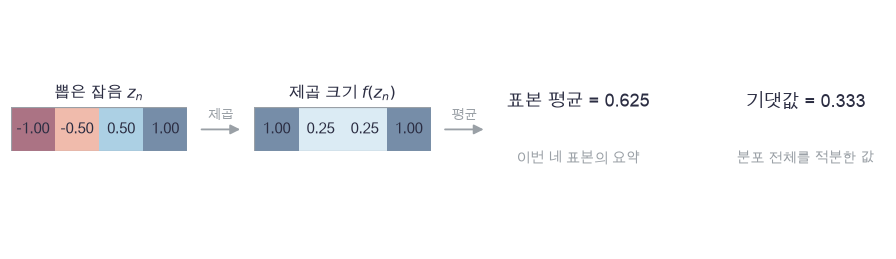

In [3]:
plot_mean_flow(hand_z, hand_values, hand_mean, uniform_exact)

🔍 **확인** · 앞의 두 판은 같은 네 관측에 제곱을 적용한 것입니다. 뒤의 두 숫자는 대상이 다릅니다. $0.625$는 고정 목록의 평균이고, $1/3$은 연속 분포 전체의 평균입니다. 표본 평균이 정답에서 벗어났다는 이유만으로 구현 오류라고 할 수는 없습니다.

In [4]:
def mean_loop(values):
    """표본 평균 (1/N) Σ_n f_n을 반복문으로 계산합니다. values: (N,) → 숫자."""
    total = 0.0
    for value in values:
        total += value
    return total / len(values)


def mean_vectorized(values):
    """같은 표본 평균을 NumPy로 계산합니다. values: (N,) → 숫자."""
    return float(np.mean(values))

In [5]:
# 쓰는 것: hand_values, hand_mean, uniform_exact (1절 손계산 셀)
np.testing.assert_allclose(mean_loop(hand_values), 0.625)           # 검산: 손계산한 제곱합 2.5 / 4
np.testing.assert_allclose(mean_vectorized(hand_values), hand_mean) # 검산: 반복문·벡터화·손계산이 같은 목록을 평균냄
integration_grid = np.linspace(-1, 1, 10001)
uniform_integral = np.trapezoid(0.5 * integration_grid ** 2, integration_grid)
np.testing.assert_allclose(uniform_integral, uniform_exact, atol=7e-9, rtol=0)   # 검산: 촘촘한 사다리꼴 적분 = 닫힌식 1/3
print("손계산·반복문·벡터화 검산 통과 · 수치 적분", uniform_integral)

손계산·반복문·벡터화 검산 통과 · 수치 적분 0.33333334


📎 **코드** · `np.trapezoid(y, x)`는 이웃한 점 사이를 사다리꼴로 보고 넓이를 더합니다. 위 격자 적분의 오차는 **결정적인 수치 근사 오차**입니다. 아래 난수 평균의 흔들림과는 원인이 다릅니다.

In [6]:
# 쓰는 것: mean_vectorized (1절 구현) · uniform_exact (1절 손계산 셀)
uniform_rng = np.random.default_rng(2701)
uniform_samples = uniform_rng.uniform(-1, 1, size=10000)
uniform_estimate = mean_vectorized(uniform_samples ** 2)
print(f"10,000개 MC 평균 {uniform_estimate:.6f} · 이번 오차 {uniform_estimate - uniform_exact:+.6f}")

10,000개 MC 평균 0.335275 · 이번 오차 +0.001941


### ✏️ 연습 1 · 표본 축을 평균내기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

받은 함숫값 N개를 평균내는 한 줄을 채웁니다.

In [7]:
def exercise_mean(values):
    """values: (N,) → 표본 평균 숫자 하나."""
    # 구현할 내용: 표본 축의 산술 평균
    raise NotImplementedError
    return estimate

In [8]:
def check_mean(candidate):
    """네 제곱값의 합 2.5를 4로 나눈 손계산과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([1.0, 0.25, 0.25, 1.0])), 0.625)   # 검산: 2.5 / 4
    print("연습 1 통과 · 표본 축 평균")
run_check(check_mean, exercise_mean, hint="np.mean(values)")

☐ exercise_mean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: np.mean(values)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
estimate = np.mean(values)
```

</details>

## 🔑 2. 같은 실험을 다시 하면: 분산과 표준오차

**이 절에서 가져갈 것:** 독립 표본 N개 평균의 분산은 원래 함숫값 분산의 $1/N$이고, 표준오차는 $1/\sqrt N$ 규모입니다. 행 안의 관측과 행 사이의 반복을 구분합니다.

앞 절의 10,000개를 다시 뽑으면 평균이 조금 달라집니다. 이번 평균이 얼마나 정확한지 한 숫자로 나타내려면, **함숫값 자체의 흔들림**과 **평균의 흔들림**을 구분해야 합니다.

> **용어**
>
> - **분산·표준편차(variance·SD)**: 평균에서 벗어난 제곱 거리의 기대값과 그 제곱근입니다.
> - **표준오차(standard error, SE)**: 표본을 다시 뽑을 때 추정량이 가지는 표준편차입니다. 관측값의 SD와 다릅니다.
> - **독립 동일분포(i.i.d.)**: 각 표본이 같은 분포에서 나오며 다른 표본의 값에 의존하지 않는다는 가정입니다.

독립이므로 다른 표본 사이의 공분산이 0입니다. $F_n=f(Z_n)$에 대해

$$\mathrm{Var}(\widehat\mu_N)=\frac1{N^2}\sum_n\mathrm{Var}(F_n)
=\frac{\mathrm{Var}(F)}N,\qquad
\widehat{\mathrm{SE}}=\frac{s_F}{\sqrt N},\quad
s_F^2=\frac1{N-1}\sum_n(F_n-\bar F)^2.$$

여기서는 $\mathbb E[Z^4]=1/5$이므로 $\mathrm{Var}(Z^2)=1/5-1/9=4/45$도 정확히 압니다.
반복 R회의 함숫값은 `(R,N)`에 담습니다. `axis=1`을 줄인 평균·SE는 `(R,)`입니다.

> **코드** · `values.std(ddof=1)`은 분모가 N−1인 표본 표준편차입니다. N은 2 이상이어야 합니다. `np.column_stack([a, b])`는 같은 길이의 두 배열을 두 열로 붙입니다.

In [9]:
# 쓰는 것: uniform_exact (1절 손계산 셀)
replication_rng = np.random.default_rng(2702)
replication_values = replication_rng.uniform(-1, 1, size=(4, 6)) ** 2
replication_means = replication_values.mean(axis=1)
replication_ses = replication_values.std(axis=1, ddof=1) / np.sqrt(6)
replication_table = np.column_stack([replication_means, replication_ses])
print("함숫값", replication_values.shape, "→ 평균과 SE", replication_table.shape)

함숫값 (4, 6) → 평균과 SE (4, 2)


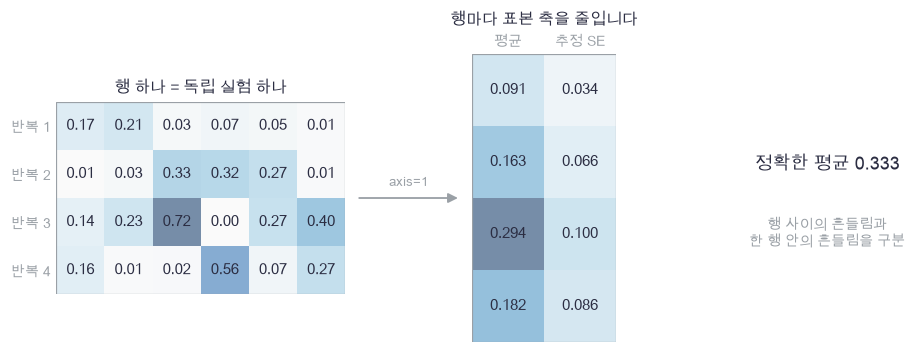

In [10]:
plot_replication_flow(replication_values, replication_table, uniform_exact)

🔍 **확인** · 왼쪽의 행 네 개는 서로 다른 실험입니다. 각 행의 여섯 값으로 가운데 평균과 SE를 만듭니다. 평균 옆 SE가 작다는 것은 추정된 흔들림이 작다는 뜻이며, 이번 평균이 참값과 정확히 같거나 반드시 그 SE 안에 있다는 뜻은 아닙니다.

In [11]:
def mean_and_se(values):
    """i.i.d. 함숫값의 평균과 추정 SE = 표본 SD / √N. values: (N,), N≥2 → 숫자 둘."""
    assert len(values) >= 2, "표준오차를 추정하려면 표본이 두 개 이상이어야 합니다"
    return float(values.mean()), float(values.std(ddof=1) / np.sqrt(len(values)))

In [12]:
hand_mean2, hand_se2 = mean_and_se(np.array([0.0, 1.0, 2.0, 3.0]))
np.testing.assert_allclose(hand_mean2, 1.5)                          # 검산: 손계산 평균 6 / 4
np.testing.assert_allclose(hand_se2, np.sqrt(5 / 12))                # 검산: 제곱편차 합 5 / (4−1) / 4
exact_variance = 1 / 5 - (1 / 3) ** 2
np.testing.assert_allclose(exact_variance, 4 / 45)                   # 검산: E[Z⁴] − E[Z²]²
print("평균·SE 손계산 검산 통과")

평균·SE 손계산 검산 통과


In [13]:
# 쓰는 것: uniform_exact (1절) · exact_variance (2절 검산)
precision_rng = np.random.default_rng(2703)
sample_sizes = np.array([8, 32, 128, 512])
repeat_count = 600
precision_sd, precision_se = [], []
precision_means = []
for sample_count in sample_sizes:
    values = precision_rng.uniform(-1, 1, size=(repeat_count, sample_count)) ** 2
    estimates = values.mean(axis=1)                                # (R,): 서로 독립인 평균 추정치
    precision_means.append(estimates)
    precision_sd.append(estimates.std(ddof=1))                      # R회 반복에서 관측한 평균의 SD
    precision_se.append((values.std(axis=1, ddof=1) / np.sqrt(sample_count)).mean())
    print(f"N={sample_count:3d} · 반복 평균 {estimates.mean():.5f} · 반복 SD {precision_sd[-1]:.5f} · 정확한 SD {np.sqrt(exact_variance / sample_count):.5f}")
precision_theory = np.sqrt(exact_variance / sample_sizes)

N=  8 · 반복 평균 0.32936 · 반복 SD 0.10301 · 정확한 SD 0.10541
N= 32 · 반복 평균 0.33251 · 반복 SD 0.05217 · 정확한 SD 0.05270
N=128 · 반복 평균 0.33354 · 반복 SD 0.02627 · 정확한 SD 0.02635
N=512 · 반복 평균 0.33375 · 반복 SD 0.01337 · 정확한 SD 0.01318


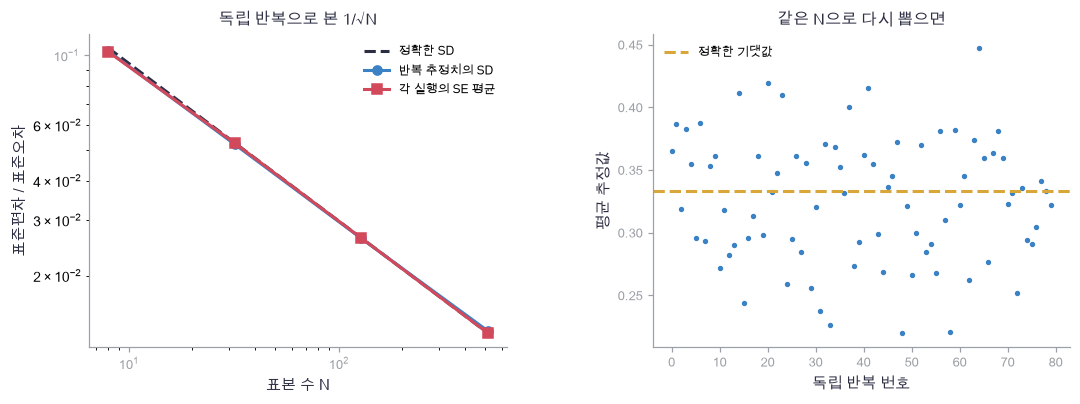

In [14]:
plot_mc_precision(sample_sizes, precision_sd, precision_theory, precision_se, precision_means[1][:80], uniform_exact)

🔍 **확인** · 왼쪽에서 N을 네 배로 늘리면 이론상 표준편차는 절반입니다. 유한한 600회 반복에서 잰 값은 그 선 주변에 놓일 수 있습니다. 오른쪽처럼 **같은 N에서도 추정치는 흔들립니다.** N이 큰 한 번의 오차가 N이 작은 한 번보다 반드시 작지는 않습니다.

여기서 바꾼 것은 같은 분포에서 뽑는 난수뿐입니다. VAE의 평가 데이터와 모델을 고정하고 잠재 $z$만 다시 뽑아 얻은 SE도 이 경우입니다. 새 데이터의 불확실성을 재려면 데이터를 다시 뽑는 반복이, 재학습의 흔들림을 재려면 모델을 다시 학습하는 반복이 따로 필요합니다. 상관된 MCMC 표본에는 위 i.i.d. 공식을 그대로 적용할 수 없습니다.

### ✏️ 연습 2 · 평균의 흔들림으로 단위 바꾸기

이미 계산한 표본 표준편차를 N개 평균의 SE로 바꿉니다.

In [15]:
def exercise_se(sample_sd, count):
    """표본 SD와 개수 → i.i.d. 평균의 추정 SE."""
    # 구현할 내용: sample_sd를 sqrt(count)로 나누기
    raise NotImplementedError
    return se

In [16]:
def check_se(candidate):
    """SD가 3이고 표본이 9개면 SE는 1입니다."""
    np.testing.assert_allclose(candidate(3.0, 9), 1.0)               # 검산: 3 / √9
    print("연습 2 통과 · 표준편차와 표준오차 구분")
run_check(check_se, exercise_se, hint="sample_sd / np.sqrt(count)")

☐ exercise_se: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: sample_sd / np.sqrt(count)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
se = sample_sd / np.sqrt(count)
```

</details>

## 🔑 3. 드문 곳을 더 자주 뽑으면: importance sampling

**이 절에서 가져갈 것:** $q$에서 뽑은 표본에 $w=p/q$를 곱하면 $p$의 기대값을 잴 수 있습니다. raw 평균과 가중치 합으로 나눈 평균은 다른 추정량입니다.

Gaussian 센서가 2를 넘는 드문 경우의 확률을 재고 싶습니다. 오른쪽에서 더 자주 뽑으면 그 사건을 자주 보지만, **원래보다 자주 뽑은 몫을 다시 낮춰야** 합니다.

> **용어**
>
> - **제안 분포(proposal) $q$**: 실제로 표본을 뽑는 분포입니다. 기대값을 알고 싶은 목표 분포는 $p$입니다.
> - **importance weight $w(z)=p(z)/q(z)$**: 뽑는 분포가 달라진 만큼 보정하는 비율입니다.
> - **지지집합(support)**: 분포가 값을 낼 수 있는 영역입니다. 필요한 영역을 $q$가 전혀 뽑지 못하면 weight로 복구할 수 없습니다.

$$\mu=\int f(z)p(z)\,dz=\int f(z)\frac{p(z)}{q(z)}q(z)\,dz,\qquad
\widehat\mu_{\mathrm{raw}}=\frac1N\sum_n w_n f(z_n),\quad z_n\sim q.$$

raw IS에는 $f(z)p(z)\ne0$인 곳에서 $q(z)>0$이 필요합니다. 기대 절댓값이 유한하면 불편 추정량이고, SE 공식에는 $wf$의 유한 분산도 필요합니다. “불편”은 반복 기대값이 참값이라는 뜻이지 한 번의 정확성 보장이 아닙니다.

정규화 상수를 모르는 목표 밀도에서도 쓸 수 있는 **self-normalized IS**는

$$\bar w_n=\frac{w_n}{\sum_j w_j},\qquad \widehat\mu_{\mathrm{SN}}=\sum_n\bar w_n f(z_n)$$

입니다. 정규화 전 밀도 $\tilde p=Cp$를 weight에 써도 공통 상수 $C$가 분자·분모에서 상쇄됩니다. 유한 N에서 일반적으로 편향이 있으며, $p(z)>0$인 전체 영역을 $q$가 포함해야 합니다. 아래는 먼저 세 상태를 모두 열거해 보정 항등식을 봅니다. $f(z)=z^2$입니다.

> **코드** · `np.stack([is_p, is_q])`는 `(3,)`인 두 확률 배열을 행으로 쌓아 `(2, 3)` 표를 만듭니다.

In [17]:
is_states = np.array([0.0, 1.0, 2.0])
is_p = np.array([0.25, 0.5, 0.25])
is_q = np.array([0.5, 0.25, 0.25])
is_weights = is_p / is_q
is_contributions = is_q * is_weights * is_states ** 2
is_exact = float(np.sum(is_p * is_states ** 2))
is_probabilities = np.stack([is_p, is_q])
print("q에서의 기여", is_contributions, "· 합", is_contributions.sum(), "· p의 기대값", is_exact)

q에서의 기여 [0.  0.5 1. ] · 합 1.5 · p의 기대값 1.5


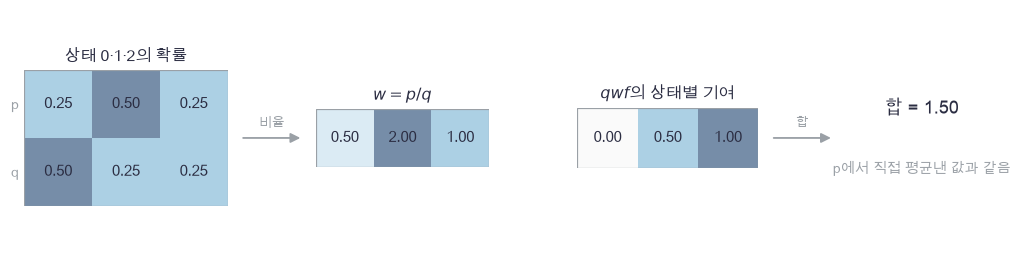

In [18]:
plot_importance_flow(is_probabilities, is_weights, is_contributions, is_exact)

🔍 **확인** · 상태 0은 $q$에서 두 배 자주 나오므로 weight가 0.5이고, 상태 1은 절반만 나오므로 weight가 2입니다. $q\times(p/q)$가 상태별로 $p$가 되므로, 모든 상태를 더한 값은 정확히 같습니다. 유한한 무작위 표본에서는 상태를 본 횟수도 흔들립니다.

로그 weight $\ell=\log p-\log q$를 먼저 계산합니다. self-normalization에서는 공통 최댓값을 빼도 비율이 같습니다. **raw IS에서는 그 상수를 버리면 안 됩니다.** 아래 구현은 $f\geq0$인 경우만 다루며, raw의 합도 logsumexp로 계산합니다. signed $f$는 양·음 기여를 따로 처리해야 합니다.

> **용어** · **weight ESS** $1/\sum_n\bar w_n^2$: 현재 표본에서 가중치가 얼마나 고르게 퍼졌는지 보는 진단값입니다. N개의 균등 weight면 N, 한 점에 몰리면 1에 가깝습니다. 놓친 영역이나 실제 적분 오차를 보장하지 않습니다.
>
> **코드** · `positive = values > 0`은 양수 함숫값만 고르는 마스크입니다. $f=0$인 항은 합에 기여하지 않으므로 로그를 취하기 전에 제외합니다.

In [19]:
def logsumexp_1d(values):
    """log Σ exp를 안정화합니다. values: (N,), N>0, −∞ 허용 → 숫자."""
    biggest = values.max()
    if np.isneginf(biggest):
        return -np.inf
    return float(biggest + np.log(np.exp(values - biggest).sum()))


def normalized_weights(log_weights):
    """log weight에서 합 1의 weight를 만듭니다. (N,) → (N,). 모두 −∞인 경우는 거부합니다."""
    biggest = log_weights.max()
    assert np.isfinite(biggest), "관측한 표본 중 유한한 양의 weight가 적어도 하나 있어야 합니다"
    shifted = np.exp(log_weights - biggest)
    return shifted / shifted.sum()

In [20]:
def importance_estimates(values, log_weights):
    """비음수 함숫값의 raw IS·self-normalized IS·weight ESS. 두 입력 (N,) → 숫자 셋."""
    # 쓰는 것: logsumexp_1d, normalized_weights (3절 구현)
    assert np.all(values >= 0), "이 작은 구현은 0 이상의 함숫값만 지원합니다"
    positive = values > 0
    raw = 0.0
    if np.any(positive):
        log_terms = log_weights[positive] + np.log(values[positive])
        raw = float(np.exp(logsumexp_1d(log_terms) - np.log(len(values))))
    normalized = normalized_weights(log_weights)
    self_normalized = float(np.sum(normalized * values))
    ess = float(1 / np.sum(normalized ** 2))
    return raw, self_normalized, ess


def normal_logpdf(z, mean=0.0, std=1.0):
    """정규분포의 로그 밀도 −½log(2πσ²) − (z−μ)²/(2σ²). z: 임의 모양 → 같은 모양."""
    return -0.5 * np.log(2 * np.pi * std ** 2) - 0.5 * ((z - mean) / std) ** 2

In [21]:
# 쓰는 것: is_p, is_q, is_weights, is_contributions, is_exact (3절 손계산 셀)
np.testing.assert_allclose(is_q * is_weights, is_p)                 # 검산: q × p/q = p
np.testing.assert_allclose(is_contributions.sum(), is_exact)        # 검산: 정확한 유한합의 항등식
small_raw, small_sn, small_ess = importance_estimates(np.array([0.0, 1.0, 4.0]), np.log(np.array([0.5, 2.0, 1.0])))
np.testing.assert_allclose([small_raw, small_sn, small_ess], [2.0, 12 / 7, 7 / 3])   # 검산: raw 6/3, SN 6/3.5, ESS 3.5²/5.25
np.testing.assert_allclose(normalized_weights(np.array([1000.0, 1000.0])), [0.5, 0.5])   # 검산: 큰 공통 로그 상수는 비율에서 사라짐
zero_target = importance_estimates(np.array([1.0, 0.0]), np.array([-np.inf, 0.0]))
np.testing.assert_allclose(zero_target, [0.0, 0.0, 1.0])              # 검산: f>0인 곳의 목표 weight가 0이면 기여도 0
print("importance 항등식·두 추정량·로그 안정화·0 weight 검산 통과")

importance 항등식·두 추정량·로그 안정화·0 weight 검산 통과


📎 **실험 설정** · 이제 $p=\mathcal N(0,1)$, $f(z)=\mathbf1[z>2]$로 바꿉니다. 정확한 꼬리 확률은 $\tfrac12\operatorname{erfc}(2/\sqrt2)$입니다. `math.erfc`는 Gaussian 꼬리 적분을 구하는 표준 라이브러리 함수입니다.
세 proposal은 $\mathcal N(0,1)$, $\mathcal N(2.5,1)$, $\mathcal N(-1.5,1)$입니다. 모두 전체 실수축을 포함하지만 사건을 보는 빈도는 다릅니다. 각 설정에서 **독립된 400회**, 회당 1,000개를 뽑습니다. 아래 SD는 한 추정치가 다시 뽑힐 때의 흔들림이며, 400회 평균의 SE가 아닙니다.

> **코드** · `zip(이름들, 평균들, 표준편차들, ESS들)`은 같은 위치의 항목을 하나씩 묶어 반복합니다. 한 proposal의 이름과 결과를 같은 줄에 출력할 때 씁니다.

In [22]:
# 쓰는 것: importance_estimates, normal_logpdf (3절 구현)
importance_rng = np.random.default_rng(2704)
proposal_means = [0.0, 2.5, -1.5]
proposal_names = ["그대로 q=p", "오른쪽 q", "왼쪽 q"]
importance_runs = np.empty((3, 400, 3))                            # (proposal, 반복, raw/SN/ESS)
tail_exact = 0.5 * math.erfc(2 / np.sqrt(2))
for proposal_index, proposal_mean in enumerate(proposal_means):
    for repeat in range(400):
        z = importance_rng.normal(proposal_mean, 1.0, size=1000)
        log_weights = normal_logpdf(z) - normal_logpdf(z, proposal_mean)
        importance_runs[proposal_index, repeat] = importance_estimates((z > 2).astype(float), log_weights)
importance_means = importance_runs[:, :, :2].mean(axis=1)
importance_sds = importance_runs[:, :, :2].std(axis=1, ddof=1)
importance_ess = importance_runs[:, :, 2].mean(axis=1)
importance_grid = np.linspace(-5, 6, 401)
target_pdf = np.exp(normal_logpdf(importance_grid))
proposal_pdfs = [np.exp(normal_logpdf(importance_grid, mean)) for mean in proposal_means]
for name, means, sds, ess in zip(proposal_names, importance_means, importance_sds, importance_ess):
    print(name, "· raw/SN 평균", means, "· 반복 SD", sds, "· 평균 ESS", round(float(ess), 1))
print("정확한 꼬리 확률", tail_exact, "· proposal별 사건을 한 번도 못 본 비율", (importance_runs[:, :, 0] == 0).mean(axis=1))

그대로 q=p · raw/SN 평균 [0.02265 0.02265] · 반복 SD [0.0047 0.0047] · 평균 ESS 1000.0
오른쪽 q · raw/SN 평균 [0.02276 0.02588] · 반복 SD [0.00108 0.00754] · 평균 ESS 25.3
왼쪽 q · raw/SN 평균 [0.0219  0.01965] · 반복 SD [0.05718 0.04584] · 평균 ESS 137.8
정확한 꼬리 확률 0.022750131948179216 · proposal별 사건을 한 번도 못 본 비율 [0.     0.     0.8025]


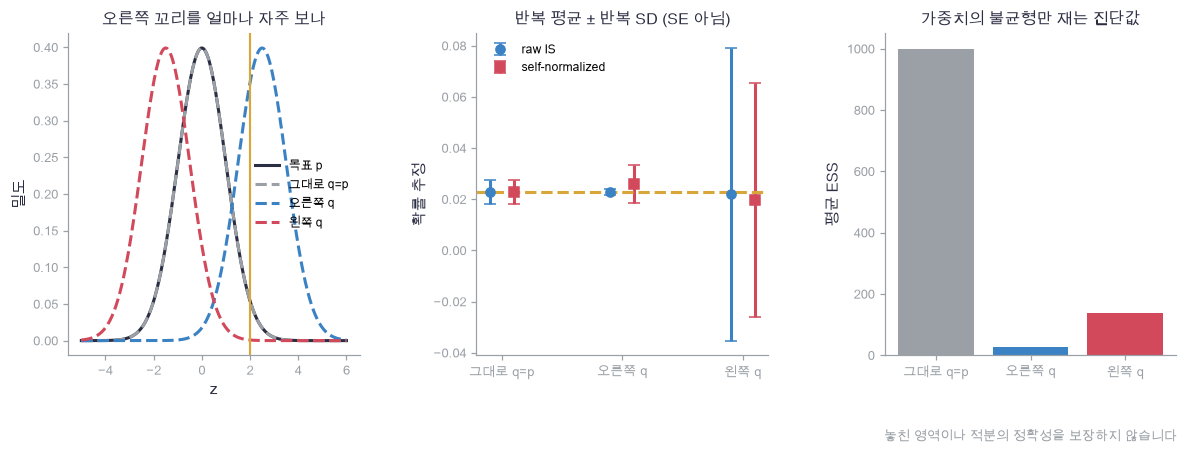

In [23]:
plot_importance_results(importance_grid, target_pdf, proposal_pdfs, proposal_names, importance_means, importance_sds, importance_ess, tail_exact)

🔍 **확인** · 오른쪽에서 뽑으면 사건을 더 자주 볼 수 있지만, 좋은 정도는 **이번 적분 $f$**에 달려 있습니다. 가운데는 독립 반복의 평균과 SD입니다. raw가 불편이어도 400회 평균이 참값과 정확히 같지는 않습니다. self-normalized와 raw의 평균·분산도 서로 다를 수 있습니다.
ESS가 큰 `q=p`도 드문 사건을 거의 못 볼 수 있습니다. 다음 반례는 더 분명합니다. 두 상태에 $p=(0.5,0.5)$가 있지만 $q=(1,0)$이면 상태 1의 기여는 영원히 보지 못합니다. 관측한 weight가 전부 같아서 ESS는 N이어도 추정값은 틀립니다.

In [24]:
# 쓰는 것: importance_estimates (3절 구현)
missing_values = np.zeros(8)                                       # q는 상태 0만 뽑고 f(0)=0
missing_logweights = np.full(8, np.log(0.5))                        # 관측한 상태에서만 p/q=0.5
missing_raw, missing_sn, missing_ess = importance_estimates(missing_values, missing_logweights)
np.testing.assert_allclose([missing_raw, missing_sn, missing_ess], [0.0, 0.0, 8.0])   # 검산: 잘못된 support인데도 관측 ESS=8
missing_exact = 0.5 * 0 + 0.5 * 1
print("support 반례 · 참값", missing_exact, "· 추정치", missing_raw, "· ESS", missing_ess)

support 반례 · 참값 0.5 · 추정치 0.0 · ESS 8.0


📎 **참고** · importance sampling의 보정 조건과 self-normalization, ESS의 한계는 [Art Owen, Monte Carlo theory, methods and examples 9장](https://artowen.su.domains/mc/Ch-var-is.pdf)에 정리되어 있습니다. 위 수치 예제와 유한 상태 반례는 그 식을 직접 계산한 것입니다.

### ✏️ 연습 3 · 로그 weight를 합 1로 만들기

최댓값을 먼저 빼고 지수화한 뒤 합으로 나누는 두 줄을 채웁니다.

In [25]:
def exercise_normalize(log_weights):
    """유한한 log weight (N,) → 정규화한 weight (N,)."""
    # 구현할 내용: shifted와 normalized 계산
    raise NotImplementedError
    return normalized

In [26]:
def check_normalize(candidate):
    """weight 비율 1:3과 큰 공통 로그 상수의 불변성을 확인합니다."""
    logs = np.log(np.array([1.0, 3.0])) + 1000
    np.testing.assert_allclose(candidate(logs), [0.25, 0.75])        # 검산: 비율 1:3의 합 1 가중치
    print("연습 3 통과 · log weight 안정화")
run_check(check_normalize, exercise_normalize, hint="최댓값을 뺀 np.exp 뒤에 합으로 나누기")

☐ exercise_normalize: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 최댓값을 뺀 np.exp 뒤에 합으로 나누기


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
shifted = np.exp(log_weights - log_weights.max())
normalized = shifted / shifted.sum()
```

</details>

## 🔑 4. 잡음을 고정하고 움직이면: pathwise 기울기

**이 절에서 가져갈 것:** 분포의 표본을 $Z=\theta+\sigma\epsilon$으로 쓰면 $\theta$가 움직이는 경로를 미분할 수 있습니다. 고정 $\epsilon$의 표본 목적과 분포의 기대 목적을 따로 검산합니다.

센서의 위치 $\theta$를 조절해 목표 $a=1.5$ 가까이 보내고 싶습니다. 잡음 크기 $\sigma=0.6$은 고정합니다. 표준정규 $\epsilon$은 $\theta$에 의존하지 않습니다.

> **용어**
>
> - **재매개화(reparameterization)**: 분포에서 뽑는 연산을 모수와 별도의 난수에 대한 식으로 바꾸는 것입니다.
> - **pathwise gradient**: 같은 난수를 고정한 채 표본이 모수를 따라 움직이는 경로를 미분한 기울기입니다.

$$J(\theta)=\mathbb E_{\epsilon\sim\mathcal N(0,1)}[(\theta+\sigma\epsilon-a)^2]
=(\theta-a)^2+\sigma^2,\qquad J'(\theta)=2(\theta-a).$$

표본 N개를 고정하면 다른 함수가 됩니다.

$$\widehat J_N(\theta;\epsilon)=\frac1N\sum_n(\theta+\sigma\epsilon_n-a)^2,\qquad
\partial_\theta\widehat J_N=\frac1N\sum_n2(\theta+\sigma\epsilon_n-a).$$

$\epsilon,z,f(z)$는 `(N,)`, 평균 손실과 기울기는 숫자입니다. 이 Gaussian·제곱손실에서는 미분과 기대값의 교환이 유한 모멘트로 정당화됩니다. 모든 샘플링 함수에서 자동으로 성립하는 규칙은 아닙니다.
손계산으로 $\theta=-0.5$, $\epsilon=(-1,0.25,1.5)$를 넣으면 표본 기울기는 $-3.7$, 정확한 기대 기울기는 $-4$입니다.

In [27]:
path_theta, path_sigma, path_target = -0.5, 0.6, 1.5
path_eps = np.array([-1.0, 0.25, 1.5])                              # (3,): 고정한 잡음 목록
path_latent = path_theta + path_sigma * path_eps
path_losses = (path_latent - path_target) ** 2
path_gradients = 2 * (path_latent - path_target)
path_table = np.column_stack([path_losses, path_gradients])
path_mean_gradient = float(path_gradients.mean())
path_exact_gradient = 2 * (path_theta - path_target)
print("표본 기울기", path_mean_gradient, "· 기대 목적의 기울기", path_exact_gradient)

표본 기울기 -3.7000000000000006 · 기대 목적의 기울기 -4.0


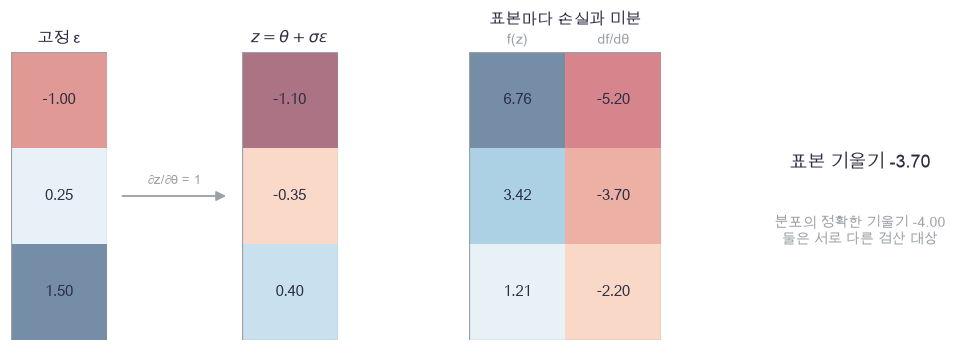

In [28]:
plot_pathwise_flow(path_eps, path_latent, path_table, path_mean_gradient, path_exact_gradient)

🔍 **확인** · 앞의 잡음 세 개를 그대로 두고 $\theta$를 조금 바꾸면 모든 $z$가 같은 만큼 움직입니다. 가운데 $df/d\theta=2(z-a)$를 평균낸 값이 **이번 표본 목적의 미분**입니다. 이를 −4와 억지로 같게 만드는 검사는 잘못된 검사입니다.

In [29]:
def gaussian_loss_grad(theta, sigma, eps, target):
    """고정 ε에서 Gaussian 제곱손실의 평균과 θ pathwise 기울기. eps: (N,) → 숫자 둘."""
    residual = theta + sigma * eps - target                         # (N,): z − a
    return float(np.mean(residual ** 2)), float(np.mean(2 * residual))

In [30]:
# 쓰는 것: path_theta, path_sigma, path_eps, path_target, path_exact_gradient (4절 손계산 셀)
sample_loss, sample_gradient = gaussian_loss_grad(path_theta, path_sigma, path_eps, path_target)
finite_step = 1e-5
loss_plus = gaussian_loss_grad(path_theta + finite_step, path_sigma, path_eps, path_target)[0]
loss_minus = gaussian_loss_grad(path_theta - finite_step, path_sigma, path_eps, path_target)[0]
sample_difference = (loss_plus - loss_minus) / (2 * finite_step)
np.testing.assert_allclose(sample_gradient, -3.7)                   # 검산: 고정 목록의 손계산 기울기
np.testing.assert_allclose(sample_gradient, sample_difference, atol=1e-9)   # 검산: 같은 ε의 표본 미분 = 중심차분
population_plus = (path_theta + finite_step - path_target) ** 2 + path_sigma ** 2
population_minus = (path_theta - finite_step - path_target) ** 2 + path_sigma ** 2
np.testing.assert_allclose((population_plus - population_minus) / (2 * finite_step), path_exact_gradient, atol=1e-9)   # 검산: 닫힌식 기대 목적의 미분
print("두 종류의 미분 검산 통과 · 표본", sample_gradient, "· 기대 목적", path_exact_gradient)

두 종류의 미분 검산 통과 · 표본 -3.7000000000000006 · 기대 목적 -4.0


In [31]:
# 쓰는 것: path_theta, path_sigma, path_target, path_exact_gradient (4절 손계산 셀) · mean_and_se (2절)
gradient_rng = np.random.default_rng(2705)
gradient_eps = gradient_rng.normal(size=(600, 64))                  # (R, N): 독립 표본 묶음
gradient_runs = (2 * (path_theta + path_sigma * gradient_eps - path_target)).mean(axis=1)
gradient_mean, gradient_mean_se = mean_and_se(gradient_runs)
print(f"600회 기울기의 평균 {gradient_mean:.5f} · 이 평균의 SE {gradient_mean_se:.5f} · 정답 {path_exact_gradient:.5f}")
print("한 번(N=64)의 기울기 정확한 SD", 2 * path_sigma / np.sqrt(64))

600회 기울기의 평균 -4.00920 · 이 평균의 SE 0.00652 · 정답 -4.00000
한 번(N=64)의 기울기 정확한 SD 0.15


🔍 **확인** · 이제야 기대값에 대한 검증을 합니다. 독립적인 잡음 묶음 600개에서 얻은 기울기들을 평균내어 −4와 비교합니다. 출력 SE는 **600회 평균**의 표준오차입니다. 한 번의 기울기 추정치의 SD와는 $\sqrt{600}$ 규모가 다릅니다.
아래에서는 기울기를 실제 갱신에 씁니다. 한 스텝마다 새로운 $\epsilon$을 뽑고 $\theta\leftarrow\theta-0.12\widehat g$로 갱신합니다. 그림의 세로축은 잡음 있는 학습 손실 대신 **닫힌식 $J(\theta)$**로 평가합니다.

> **코드** · `_, gradient = ...`에서 `_`는 돌려받았지만 쓰지 않는 손실값입니다. 갱신에는 기울기만 쓰고, 그림의 목적값은 닫힌식으로 따로 계산합니다.

In [32]:
# 쓰는 것: gaussian_loss_grad (4절 구현) · path_sigma, path_target (4절 손계산 셀)
training_batches = [4, 128]
training_steps = np.arange(61)
theta_paths = np.empty((2, 61))
for experiment, batch_size in enumerate(training_batches):
    training_rng = np.random.default_rng(2710 + experiment)
    theta = -2.0
    theta_paths[experiment, 0] = theta
    for step in range(60):
        eps = training_rng.normal(size=batch_size)                 # 매 갱신마다 새 독립 잡음
        _, gradient = gaussian_loss_grad(theta, path_sigma, eps, path_target)
        theta -= 0.12 * gradient
        theta_paths[experiment, step + 1] = theta
exact_training_losses = (theta_paths - path_target) ** 2 + path_sigma ** 2
training_labels = ["표본 N=4", "표본 N=128"]
for label, path, losses in zip(training_labels, theta_paths, exact_training_losses):
    print(label, f"· 최종 θ {path[-1]:.5f} · 정확한 J {losses[-1]:.5f}")

표본 N=4 · 최종 θ 1.36148 · 정확한 J 0.37919
표본 N=128 · 최종 θ 1.49081 · 정확한 J 0.36008


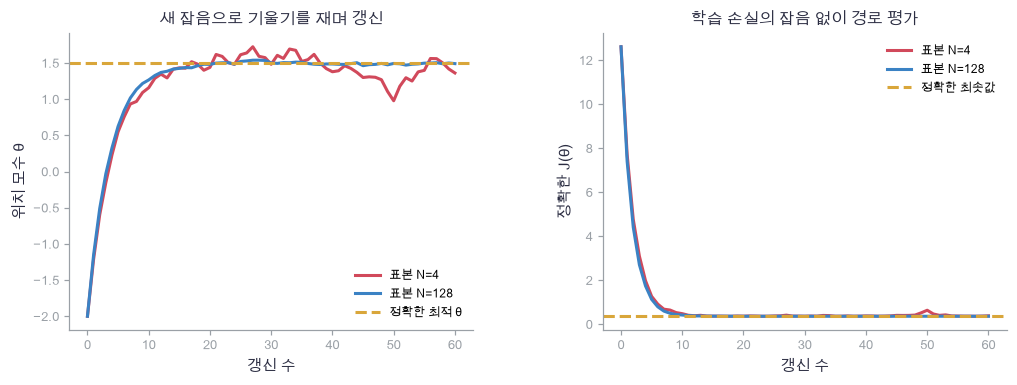

In [33]:
plot_optimization(training_steps, theta_paths, exact_training_losses, training_labels, path_target, path_sigma ** 2)

🔍 **확인** · 최적 위치는 $a$이고 최솟값은 남은 잡음 분산 $\sigma^2$입니다. 큰 표본은 기울기 잡음을 줄이는 대신 한 갱신에 더 많은 표본을 씁니다. 두 경로는 같은 갱신 수를 비교한 예시이며, 같은 계산 예산의 성능 비교는 아닙니다. 한 seed의 경로를 모든 실행의 보장으로 읽지 마세요.

📎 [25 VAE](25_vae.ipynb)의 $z=\mu+\sigma\epsilon$도 같은 경로 미분입니다. [32 DSM](32_score_matching.ipynb)의 $x+\sigma\epsilon$은 잡음 있는 학습 쌍을 만들며, 신경망 모수의 미분을 검사할 때는 그 잡음과 학습 쌍을 고정합니다. 재매개화와 기대 목적의 연결은 [Kingma·Welling의 원논문](https://arxiv.org/abs/1312.6114), 추정기별 조건은 [Mohamed 등(2020), 5절](https://www.jmlr.org/papers/volume21/19-346/19-346.pdf)을 참고할 수 있습니다.

### ✏️ 연습 4 · 표본 경로를 따라 미분하기

같은 eps를 고정했을 때 θ에 대한 평균 기울기 한 줄을 채웁니다.

In [34]:
def exercise_pathwise(theta, sigma, eps, target):
    """고정한 Gaussian 잡음 목록의 θ 기울기. eps: (N,) → 숫자."""
    # 구현할 내용: 2 * (theta + sigma * eps - target)의 평균
    raise NotImplementedError
    return gradient

In [35]:
def check_pathwise(candidate):
    """표본 잔차 −2.6, −1.85, −1.1의 두 배 평균을 확인합니다."""
    actual = candidate(-0.5, 0.6, np.array([-1.0, 0.25, 1.5]), 1.5)
    np.testing.assert_allclose(actual, -3.7)                        # 검산: 고정 표본 기울기 −3.7
    print("연습 4 통과 · 표본의 경로 미분")
run_check(check_pathwise, exercise_pathwise, hint="분포의 정확한 미분 대신 받은 eps를 사용하세요")

☐ exercise_pathwise: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 분포의 정확한 미분 대신 받은 eps를 사용하세요


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = np.mean(2 * (theta + sigma * eps - target))
```

</details>

## 🔑 5. 이산 선택의 확률을 움직이면: score-function과 baseline

**이 절에서 가져갈 것:** 표본 자체를 미분할 수 없더라도 **로그 확률의 모수 미분**으로 기대값을 미분할 수 있습니다. baseline은 현재 표본과의 의존성을 확인한 뒤 뺍니다.

이번에는 연속 센서값 대신 선택 하나를 뽑습니다. $b=0$이면 보상 1, $b=1$이면 보상 4입니다. 선택 확률 $p=\mathrm{sigmoid}(\theta)$를 조절하고 싶습니다. $b=\mathbf1[u<p]$를 그대로 미분하면 대부분의 $u$에서 0이어서 기대 보상의 미분을 얻지 못합니다.

> **용어**
>
> - **score-function estimator**: $\partial_\theta\log p_\theta(b)$에 함숫값을 곱해 평균내는 기울기 추정량입니다. 여기의 score는 **모수** 미분이고, 32번의 데이터 $x$에 대한 score와 미분 대상이 다릅니다.
> - **baseline $c$**: 기댓값 기울기를 바꾸지 않고 분산을 조절하려고 함숫값에서 빼는 기준값입니다. 아무 기준이나 분산을 낮추는 것은 아닙니다.

$$J(\theta)=\sum_{b\in\{0,1\}}p_\theta(b)r(b),\qquad
J'(\theta)=\sum_b p_\theta(b)r(b)\partial_\theta\log p_\theta(b)
=\mathbb E[r(b)(b-p)].$$

여기서는 $r$가 $\theta$에 직접 의존하지 않습니다. 직접 의존한다면 $\mathbb E[\partial_\theta r_\theta(b)]$ 항도 필요합니다. 유한한 두 상태의 합이므로 위 미분 교환은 직접 확인할 수 있습니다.
$p=0.3$이면 $J=1+3p=1.9$, $J'=3p(1-p)=0.63$입니다. 상태별 기여는 $0.7\times1\times(-0.3)=-0.21$, $0.3\times4\times0.7=0.84$입니다.

In [36]:
score_p = 0.3
score_bits = np.array([0, 1])
score_probabilities = np.array([1 - score_p, score_p])
score_rewards = np.array([1.0, 4.0])
score_values = score_bits - score_p                                # (2,): 두 상태의 logit score
score_contributions = score_probabilities * score_rewards * score_values
score_exact_gradient = 3 * score_p * (1 - score_p)
score_reward_table = np.column_stack([score_rewards, score_values])
print("두 기여", score_contributions, "· 합", score_contributions.sum())

두 기여 [-0.21  0.84] · 합 0.63


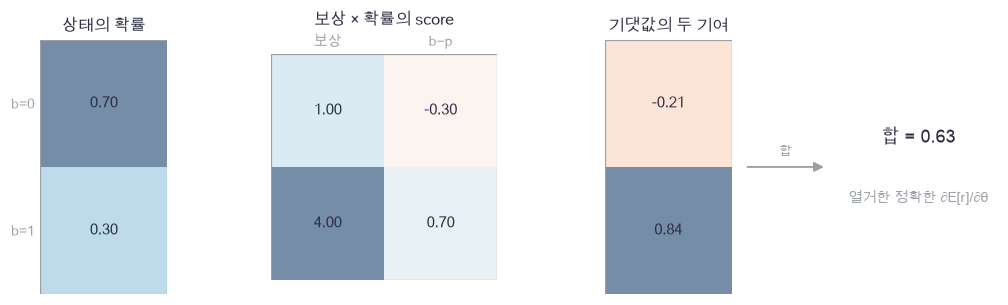

In [37]:
plot_score_flow(score_probabilities, score_reward_table, score_contributions, score_exact_gradient)

🔍 **확인** · 선택값 0과 1 사이를 미분한 것이 아닙니다. 각 선택의 **확률**이 모수에 따라 얼마나 바뀌는지 계산해 더했습니다. 샘플링 후에는 이 가중합을 $r(b)(b-p)$의 표본 평균으로 추정합니다.

상수 $c$는 $\mathbb E[b-p]=0$이므로 뺄 수 있습니다.

$$\mathbb E[(r(b)-c)(b-p)]=J'(\theta)-c\,\underbrace{\mathbb E[b-p]}_0=J'(\theta).$$

현재 모수를 고정했을 때 $c$가 현재 선택 표본과 독립이면 같은 주장이 성립합니다. 앞선 독립 자료에서 학습한 baseline을 고정해서 쓰는 것도 이 경우입니다. 여기서는 열거로 고른 **고정 숫자 3.1**을 씁니다. 이 특별한 두 상태 예제에서는 두 기여 $(r-c)(b-p)$가 모두 0.63이 됩니다. 일반 문제에서 분산이 0이라는 보장은 없습니다.

In [38]:
def bernoulli_score_gradient(bits, probability, rewards, baseline=0.0):
    """Bernoulli logit 기울기의 표본 평균 (r(b)−c)(b−p). bits: (N,), rewards: (2,) → 숫자."""
    contributions = (rewards[bits] - baseline) * (bits - probability)
    return float(contributions.mean())

In [39]:
# 쓰는 것: score_bits, score_p, score_rewards, score_probabilities, score_exact_gradient (5절 손계산 셀)
score_raw_by_state = np.array([bernoulli_score_gradient(np.array([bit]), score_p, score_rewards) for bit in score_bits])
score_centered_by_state = np.array([bernoulli_score_gradient(np.array([bit]), score_p, score_rewards, 3.1) for bit in score_bits])
np.testing.assert_allclose(score_probabilities @ score_raw_by_state, score_exact_gradient)   # 검산: 두 상태를 정확히 열거한 기울기
np.testing.assert_allclose(score_centered_by_state, [0.63, 0.63])    # 검산: 고정 baseline 3.1의 두 기여
np.testing.assert_allclose(score_probabilities @ (score_bits - score_p), 0.0, atol=1e-15)   # 검산: score의 기대값 0
print("열거 검산 통과 · 고정 baseline은 평균을 유지합니다")

열거 검산 통과 · 고정 baseline은 평균을 유지합니다


📎 **코드** · `[표현식 for bit in score_bits]`는 상태 0과 1에 같은 계산을 반복해 목록에 담는 컴프리헨션입니다. 여기서는 무작위 실험이 아니라 가능한 상태 전체를 열거하는 데 씁니다.

In [40]:
# 쓰는 것: score_p, score_rewards, score_exact_gradient (5절 손계산 셀) · mean_and_se (2절)
score_rng = np.random.default_rng(2706)
score_draws = (score_rng.random((600, 32)) < score_p).astype(int)     # (R, N): 독립 Bernoulli 선택
score_sample_rewards = score_rewards[score_draws]
score_raw_runs = (score_sample_rewards * (score_draws - score_p)).mean(axis=1)
score_centered_runs = ((score_sample_rewards - 3.1) * (score_draws - score_p)).mean(axis=1)
for label, runs in zip(["baseline 0", "baseline 3.1"], [score_raw_runs, score_centered_runs]):
    estimate, se = mean_and_se(runs)
    print(label, f"· 600회 평균 {estimate:.6f} · 이 평균의 SE {se:.6f} · 정답 {score_exact_gradient:.6f}")

baseline 0

 · 600회 평균 0.623057 · 이 평균의 SE 0.010099 · 정답 0.630000
baseline 3.1 · 600회 평균 0.630000 · 이 평균의 SE 0.000000 · 정답 0.630000


### 🔍 같은 배치 평균을 baseline으로 쓰면 무엇이 달라지나

N개의 보상 평균 $\bar r$을 같은 N개 표본에서 빼면 현재 $r(b_i)$도 baseline에 들어갑니다. 독립 가정으로 계산하면

$$\mathbb E\!\left[\frac1N\sum_i(r_i-\bar r)(b_i-p)\right]
=\left(1-\frac1N\right)J'(\theta).$$

따라서 N=3에서는 $0.63$ 대신 $0.42$가 됩니다. **각 표본 자신을 제외한 평균** $c_{-i}=\sum_{j\ne i}r_j/(N-1)$을 쓰면, i.i.d. 표본에서 $c_{-i}$는 $b_i$와 독립이어서 불편성이 복구됩니다. 이를 leave-one-out baseline이라 합니다. 서로 다른 기여들이 baseline을 공유하므로 그 기여들을 독립이라고 놓고 SE를 계산하면 안 됩니다. 아래는 N=3의 $2^3=8$개 배치를 전부 열거합니다.

> **코드** · `[[a,b,c] for a in [0,1] for b in [0,1] for c in [0,1]]`는 세 번 선택의 모든 경우를 만듭니다. `.prod(axis=1)`은 독립인 세 선택의 확률을 행마다 곱합니다.

In [41]:
# 쓰는 것: score_p, score_rewards, score_exact_gradient (5절 손계산 셀)
all_batches = np.array([[a, b, c] for a in [0, 1] for b in [0, 1] for c in [0, 1]])
batch_probabilities = (score_p ** all_batches * (1 - score_p) ** (1 - all_batches)).prod(axis=1)
batch_rewards = score_rewards[all_batches]                         # (8, 3): 각 배치의 보상
batch_scores = all_batches - score_p
batch_mean_baseline = batch_rewards.mean(axis=1, keepdims=True)
loo_baseline = (batch_rewards.sum(axis=1, keepdims=True) - batch_rewards) / 2
enumerated_gradients = np.column_stack([
    (batch_rewards * batch_scores).mean(axis=1),
    ((batch_rewards - 3.1) * batch_scores).mean(axis=1),
    ((batch_rewards - batch_mean_baseline) * batch_scores).mean(axis=1),
    ((batch_rewards - loo_baseline) * batch_scores).mean(axis=1),
])                                                               # (8, 4): 경우별 네 추정량
baseline_means = batch_probabilities @ enumerated_gradients
baseline_variances = batch_probabilities @ (enumerated_gradients - baseline_means) ** 2
baseline_names = ["baseline 0", "고정 3.1", "같은 배치 평균", "자신 제외 평균"]
np.testing.assert_allclose(batch_probabilities.sum(), 1.0)          # 검산: 전체 경우의 확률 합 1
np.testing.assert_allclose(baseline_means, [0.63, 0.63, 0.42, 0.63]) # 검산: 같은 배치 평균만 (1−1/3)배
print("정확한 열거 평균", baseline_means, "· 분산", baseline_variances)

정확한 열거 평균 [0.63 0.63 0.42 0.63] · 분산 [0.6727 0.     0.1036 0.2331]


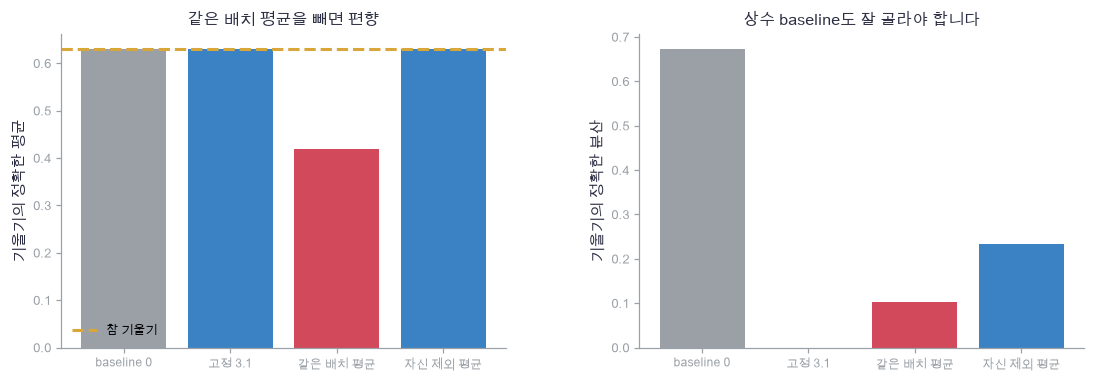

In [42]:
plot_baselines(baseline_names, baseline_means, baseline_variances, score_exact_gradient)

🔍 **확인** · 왼쪽에서 같은 배치 평균만 참 기울기보다 작습니다. 이 결과는 seed에 따른 관측이 아니라 여덟 경우를 모두 더한 **정확한 계산**입니다. 자신을 제외한 평균은 불편성을 복구하지만 분산 감소까지 보장하지 않습니다.

| 상황 | 여기서 쓸 수 있는 방법 | 확인할 것 |
|---|---|---|
| Gaussian 표본과 매끄러운 $f$ | 재매개화한 pathwise | 고정 난수 gradcheck와 기대 기울기를 따로 확인 |
| Bernoulli의 이산 선택 | score-function | 모수에 대한 로그 확률 미분, baseline의 의존성 |
| 정규화 상수만 모르는 밀도의 기대값 | self-normalized IS | support, weight 불균형, 유한 N의 편향 |

📎 score-function과 상수 baseline의 유도·조건은 [Mohamed 등(2020), 4절과 7.4.3절](https://www.jmlr.org/papers/volume21/19-346/19-346.pdf)을 참고할 수 있습니다. 같은 배치 평균의 편향과 위 leave-one-out 결과는 여기서 직접 열거해 확인했습니다.

### ✏️ 연습 5 · 로그 확률의 모수 미분

Bernoulli logit의 score는 b−p입니다. 고정 baseline을 뺀 기여의 평균을 채웁니다.

In [43]:
def exercise_score(bits, probability, rewards, baseline):
    """bits: (N,), rewards: (2,), 고정 baseline → logit 기울기의 표본 평균."""
    # 구현할 내용: (rewards[bits] - baseline) * (bits - probability)의 평균
    raise NotImplementedError
    return gradient

In [44]:
def check_score(candidate):
    """선택 0,1의 두 기여가 baseline 3.1에서 모두 0.63인지 봅니다."""
    actual = candidate(np.array([0, 1]), 0.3, np.array([1.0, 4.0]), 3.1)
    np.testing.assert_allclose(actual, 0.63)                        # 검산: (0.63 + 0.63) / 2
    print("연습 5 통과 · score-function 표본 기울기")
run_check(check_score, exercise_score, hint="선택 확률 p에 대한 미분이 아니라 logit θ에 대한 score입니다")

☐ exercise_score: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 선택 확률 p에 대한 미분이 아니라 logit θ에 대한 score입니다


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = np.mean((rewards[bits] - baseline) * (bits - probability))
```

</details>

## ✏️ 6. 직접 변형해서 확인합니다

절 연습은 방금 읽은 한 줄을 옮기는 문제였습니다. 여기서는 확률 가중합, 반복 축, weight 진단, 잡음 크기의 미분으로 한 단계씩 바꿉니다. 모두 손계산이 가능한 작은 배열을 씁니다.

### ✏️ 연습 A · 표본이 아니라 전체 분포가 주어졌다면

상태와 그 확률이 주어졌습니다. 제곱의 정확한 기대값을 확률 가중합으로 구합니다.

In [45]:
def exercise_second_moment(states, probabilities):
    """유한 상태 (K,)와 확률 (K,) → 정확한 E[Z²]."""
    # 구현할 내용: probabilities * states**2를 모두 더하기
    raise NotImplementedError
    return expectation

In [46]:
def check_second_moment(candidate):
    """상태 −1,0,2와 확률 0.2,0.5,0.3의 제곱 평균은 1.4입니다."""
    actual = candidate(np.array([-1.0, 0.0, 2.0]), np.array([0.2, 0.5, 0.3]))
    np.testing.assert_allclose(actual, 1.4)                         # 검산: 0.2×1 + 0.5×0 + 0.3×4
    print("연습 A 통과 · 정확한 확률 가중합")
run_check(check_second_moment, exercise_second_moment, hint="정확한 확률이 있으므로 산술 평균이 아닙니다")

☐ exercise_second_moment: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정확한 확률이 있으므로 산술 평균이 아닙니다


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
expectation = np.sum(probabilities * states ** 2)
```

</details>

### ✏️ 연습 B · 반복마다 SE 하나씩

행은 독립 반복, 열은 표본입니다. 표본 축의 SD를 구해 반복마다 SE를 반환합니다.

In [47]:
def exercise_row_se(values):
    """values: (R, N), N≥2 → 각 반복의 SE (R,)."""
    # 구현할 내용: axis=1의 표본 SD / sqrt(N)
    raise NotImplementedError
    return standard_errors

In [48]:
def check_row_se(candidate):
    """두 표본 0,2의 SE는 1이고, 2,6의 SE는 2입니다."""
    actual = candidate(np.array([[0.0, 2.0], [2.0, 6.0]]))
    np.testing.assert_allclose(actual, [1.0, 2.0])                  # 검산: 각 행의 SD / √2
    print("연습 B 통과 · 반복 축과 표본 축")
run_check(check_row_se, exercise_row_se, hint="N은 values.shape[1]입니다")

☐ exercise_row_se: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: N은 values.shape[1]입니다


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
standard_errors = values.std(axis=1, ddof=1) / np.sqrt(values.shape[1])
```

</details>

### ✏️ 연습 C · weight가 한 점에 몰리면

합이 1인 weight의 제곱합을 뒤집어 ESS를 구합니다. 이 값은 support 검사가 아님을 기억하세요.

In [49]:
def exercise_ess(normalized):
    """합 1의 weight (N,) → weight ESS 숫자."""
    # 구현할 내용: 1 / sum(normalized**2)
    raise NotImplementedError
    return ess

In [50]:
def check_ess(candidate):
    """균등 네 점이면 4, 한 점에 전부 몰리면 1입니다."""
    np.testing.assert_allclose(candidate(np.full(4, 0.25)), 4.0)    # 검산: 1 / (4×0.25²)
    np.testing.assert_allclose(candidate(np.array([1.0, 0.0, 0.0, 0.0])), 1.0)   # 검산: 1 / 1
    print("연습 C 통과 · ESS의 양 끝")
run_check(check_ess, exercise_ess, hint="정규화한 weight를 제곱해서 더합니다")

☐ exercise_ess: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정규화한 weight를 제곱해서 더합니다


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
ess = 1 / np.sum(normalized ** 2)
```

</details>

### ✏️ 연습 D · 잡음 크기까지 학습한다면

4절에서 위치 대신 $\rho=\log\sigma$를 미분합니다. $\partial z/\partial\rho=\sigma\epsilon$이므로, 잔차의 두 배에 이 항을 곱해 평균냅니다.

In [51]:
def exercise_logsigma_grad(theta, log_sigma, eps, target):
    """eps: (N,)를 고정한 제곱손실의 log σ 미분 → 숫자."""
    sigma = np.exp(log_sigma)
    residual = theta + sigma * eps - target
    # 구현할 내용: 2 * residual * sigma * eps의 평균
    raise NotImplementedError
    return gradient

In [52]:
def check_logsigma_grad(candidate):
    """θ=a=0, σ=2, ε=−1,1이면 기울기는 8입니다."""
    actual = candidate(0.0, np.log(2.0), np.array([-1.0, 1.0]), 0.0)
    np.testing.assert_allclose(actual, 8.0)                        # 검산: 두 표본 모두 2×(±2)×2×(±1)=8
    print("연습 D 통과 · 잡음 크기로 갈라지는 경로")
run_check(check_logsigma_grad, exercise_logsigma_grad, hint="σ를 미분하는지 log σ를 미분하는지 구분하세요")

☐ exercise_logsigma_grad: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: σ를 미분하는지 log σ를 미분하는지 구분하세요


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = np.mean(2 * residual * sigma * eps)
```

</details>

### ✏️ 준비도 질문 · 네 가지를 따로 확인합니다

- **설명:** 표본 평균이 정확한 적분과 다른데도 구현이 맞을 수 있는 이유, SD와 SE의 차이를 설명할 수 있나요? → 1·2절
- **수식:** importance sampling의 두 추정량과 support 조건을 쓰고, 왜 self-normalized 평균은 유한 N에서 편향될 수 있는지 말할 수 있나요? → 3절
- **구현:** 고정 $\epsilon$을 재사용한 중심차분과 독립 반복의 기대 기울기 검증을 각각 작성할 수 있나요? → 4절
- **변형 검산:** 같은 배치 평균 baseline의 편향을 열거하고, 자신을 제외한 평균이 i.i.d. 조건에서 평균을 복구하는 이유를 설명할 수 있나요? → 5절

다음 연결은 [25 VAE의 평가](25_vae.ipynb), [28 GAN의 두 목적](28_gan.ipynb), [32 DSM의 잡음 쌍](32_score_matching.ipynb)입니다. 표본을 **어디서 뽑는지**, 모수에 대해 **무엇을 미분하는지**, 결과를 **어떤 독립 반복으로 평가하는지**를 각 노트북에서 다시 적어 보세요.